# Autism detection prototype: EEG-feature graph + FT-Transformer with synthetic training data
Evaluation is Leave-One-Subject-Out on the 28 **real** children. Synthetic children are generated **inside each training fold only** from that fold's training children, and the held-out child is always real and unseen.
Cells 1-4 are unchanged. Cell 5 trains with synthetic data, Cell 6 evaluates, Cell 7 trains the final model for new children.

In [ ]:
# Cell 1: Environment Setup & Deterministic Seeding   (UNCHANGED)
!pip install -q seaborn matplotlib scikit-learn joblib

import os, sys, glob, zipfile, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, classification_report)
import joblib

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Compute Device: {device}")

Compute Device: cpu


In [ ]:
# =========================================================================
# CELL 2-3 (REPLACED): LOAD THE ORIGINAL 28 REAL CHILDREN (NO AUGMENTED CSVs)
# =========================================================================
# Upload the dataset zip to Colab (or place it next to this notebook). The cell
# finds it, unzips it (including the nested zip) and builds the model inputs.

def find_dataset_root():
    hits = glob.glob('**/Extracted Features', recursive=True)
    if hits:
        return os.path.dirname(hits[0])
    zips = [z for z in glob.glob('**/*.zip', recursive=True) if 'EEG' in z or 'MCHAT' in z.upper()]
    if not zips:
        try:
            from google.colab import files
            print("Please upload 'A_Multi-Modal_Dataset_of_EEG_Signals_and_M-CHAT_As.zip'")
            up = files.upload()
            zips = [k for k in up.keys() if k.endswith('.zip')]
        except ImportError:
            raise FileNotFoundError("Dataset zip not found. Put it in the working folder.")
    for _ in range(3):                       # unzip, including the zip inside the zip
        for z in zips:
            with zipfile.ZipFile(z) as zf:
                zf.extractall('dataset_unzipped')
        hits = glob.glob('dataset_unzipped/**/Extracted Features', recursive=True)
        if hits:
            return os.path.dirname(hits[0])
        zips = glob.glob('dataset_unzipped/**/*.zip', recursive=True)
    raise FileNotFoundError("Could not locate the 'Extracted Features' folder after unzipping.")

root = find_dataset_root()
print("Dataset folder:", root)

def read_feature(name):
    return pd.read_csv(f"{root}/Extracted Features/{name}.csv").set_index('Name')

cv_df, ent_df, skew_df = read_feature("Coefficient Of Variation"), read_feature("Entropy"), read_feature("Skewness")
ch_cols = [str(i) for i in range(1, 9)]

mchat_all = pd.concat([
    pd.read_csv(f"{root}/Raw ASD Data/Behavioral Data/ASD-M-CHAT.csv"),
    pd.read_csv(f"{root}/Raw Control Data/Behavioral Data/CTRL-M-CHAT.csv")])
mchat_all['Name'] = mchat_all['Participants'] + '.csv'
mchat_all = mchat_all.set_index('Name')

child_ids = cv_df.index.intersection(mchat_all.index)           # the 28 real children
eeg_all   = np.stack([cv_df.loc[child_ids, ch_cols].values,
                      ent_df.loc[child_ids, ch_cols].values,
                      skew_df.loc[child_ids, ch_cols].values], axis=-1).astype(np.float32)   # [28, 8, 3]
mchat_arr = mchat_all.loc[child_ids, [f'Q{q}' for q in range(1, 24)]].values.astype(np.float32)  # [28, 23]
y_all     = cv_df.loc[child_ids, 'Class'].values.astype(np.float32)                              # 1 = ASD, 0 = Control

def build_adjacency(eeg_nodes):
    adj = np.zeros((len(eeg_nodes), 8, 8), dtype=np.float32)
    for i in range(len(eeg_nodes)):
        corr = np.nan_to_num(np.corrcoef(eeg_nodes[i]), nan=0.0)
        aff = 0.5 * (corr + 1.0)
        np.fill_diagonal(aff, 1.0)
        adj[i] = aff
    return adj

N = len(y_all)
print(f"Children: {N}  (ASD = {int(y_all.sum())}, Control = {int(N - y_all.sum())})")
print(f"Majority-class accuracy (the number to beat): {max(y_all.mean(), 1 - y_all.mean())*100:.1f}%")

Please upload 'A_Multi-Modal_Dataset_of_EEG_Signals_and_M-CHAT_As.zip'


Saving A Multi-Modal Dataset of EEG Signals and M-CHAT As.zip to A Multi-Modal Dataset of EEG Signals and M-CHAT As.zip
Dataset folder: dataset_unzipped/ASD-EEG-MCHAT-Dataset
Children: 28  (ASD = 15, Control = 13)
Majority-class accuracy (the number to beat): 53.6%


In [ ]:
# =========================================================================
# CELL 4: EEGNet + GNN + FT-Transformer ARCHITECTURE   (CLASSES UNCHANGED)
# The only difference: no single global model is trained here. A fresh model is
# created inside each Leave-One-Subject-Out fold in Cell 5.
# =========================================================================
class FeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_token=32):
        super().__init__()
        self.num_features = num_features
        self.d_token = d_token
        self.weight = nn.Parameter(torch.empty(num_features, d_token))
        self.bias = nn.Parameter(torch.empty(num_features, d_token))
        nn.init.kaiming_uniform_(self.weight, a=np.sqrt(5))
        nn.init.zeros_(self.bias)
    def forward(self, x):
        return x.unsqueeze(-1) * self.weight + self.bias

class SpectralGraphConv(nn.Module):
    def __init__(self, in_dim, out_dim):
        super().__init__()
        self.weight = nn.Linear(in_dim, out_dim)
    def forward(self, x_nodes, adj):
        deg = torch.sum(adj, dim=-1, keepdim=True) + 1e-6
        deg_inv_sqrt = torch.pow(deg, -0.5)
        adj_norm = deg_inv_sqrt * adj * deg_inv_sqrt.transpose(-1, -2)
        agg = torch.bmm(adj_norm, x_nodes)
        return F.gelu(self.weight(agg))

class EEGNetGNNFTTransformer(nn.Module):
    def __init__(self, feats_per_channel=3, n_channels=8, n_mchat_items=23, d_model=32, n_heads=4, dropout=0.15):
        super().__init__()
        self.n_channels = n_channels
        self.d_model = d_model
        self.electrode_proj = nn.Sequential(nn.Linear(feats_per_channel, d_model), nn.LayerNorm(d_model), nn.GELU(), nn.Dropout(dropout))
        self.gnn1 = SpectralGraphConv(d_model, d_model)
        self.gnn2 = SpectralGraphConv(d_model, d_model)
        self.mchat_tokenizer = FeatureTokenizer(n_mchat_items, d_model)
        self.norm_mchat = nn.LayerNorm(d_model)
        self.cross_attn = nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, batch_first=True, dropout=dropout)
        self.norm_cross = nn.LayerNorm(d_model)
        self.self_attn = nn.MultiheadAttention(embed_dim=d_model, num_heads=n_heads, batch_first=True, dropout=dropout)
        self.norm_self = nn.LayerNorm(d_model)
        self.classifier = nn.Sequential(nn.Linear(d_model, 32), nn.LayerNorm(32), nn.GELU(), nn.Dropout(dropout), nn.Linear(32, 1))

    def forward(self, eeg_nodes, adj, mchat_items):
        h_nodes = self.electrode_proj(eeg_nodes)
        h_graph = self.gnn1(h_nodes, adj)
        h_graph = self.gnn2(h_graph, adj)
        mchat_tokens = self.norm_mchat(self.mchat_tokenizer(mchat_items))
        fused, attn_weights = self.cross_attn(query=h_graph, key=mchat_tokens, value=mchat_tokens)
        fused = self.norm_cross(h_graph + fused)
        s_out, _ = self.self_attn(fused, fused, fused)
        pooled = self.norm_self(fused + s_out).mean(dim=1)
        logits = self.classifier(pooled).squeeze(-1)
        return logits, attn_weights

_tmp = EEGNetGNNFTTransformer()
print(f"Architecture ready. Trainable parameters per model: {sum(p.numel() for p in _tmp.parameters() if p.requires_grad):,}")
del _tmp

Architecture ready. Trainable parameters per model: 13,569


In [ ]:
# =========== CELL 5 (SYNTHETIC DATA): generate inside each fold, train on real + synthetic, test on the real held-out child ===========
EPOCHS, BATCH_SIZE, LR, WD = 40, 32, 1.2e-3, 1e-4
SEEDS = list(range(10))       # 10 repeats; use [0, 1, 2] for a quick test
N_SYNTH_PER_REAL = 5        # synthetic children created per real training child (same class)
JITTER = 0.05               # small noise on EEG features, as a fraction of each feature's robust spread

def to_t(a):
    return torch.tensor(a, dtype=torch.float32, device=device)

def make_synthetic(train_idx, rng):
    # Uses ONLY the training children of this fold. The held-out child never influences what is generated.
    e_real, m_real, y_real = eeg_all[train_idx], mchat_arr[train_idx], y_all[train_idx]
    spread = (np.percentile(e_real, 75, axis=0) - np.percentile(e_real, 25, axis=0)) / 1.35       # robust per-feature spread [8,3]
    syn_e, syn_m, syn_y = [], [], []
    for cls in (0.0, 1.0):
        pool = np.where(y_real == cls)[0]                                                          # real children of this class
        for _ in range(N_SYNTH_PER_REAL * len(pool)):
            a, b = rng.choice(pool, 2, replace=False)                                              # two real parents of the same class
            lam = rng.uniform(0.0, 1.0)
            e = lam * e_real[a] + (1 - lam) * e_real[b]                                            # blend their EEG features
            e = e + rng.normal(0.0, JITTER, e.shape) * spread                                      # a little noise
            m = np.where(rng.random(23) < lam, m_real[a], m_real[b])                               # each M-CHAT answer copied from one parent (stays 0/1)
            syn_e.append(e); syn_m.append(m); syn_y.append(cls)
    return np.array(syn_e, np.float32), np.array(syn_m, np.float32), np.array(syn_y, np.float32)

def train_model(train_idx, seed, use_synth=True):
    rng = np.random.default_rng(seed)
    e_raw, m_raw, y_raw = eeg_all[train_idx], mchat_arr[train_idx], y_all[train_idx]
    scaler_f = RobustScaler().fit(e_raw.reshape(len(e_raw), 24))                                   # fitted on REAL training children only
    if use_synth:
        se, sm, sy = make_synthetic(train_idx, rng)
        e_raw, m_raw, y_raw = np.concatenate([e_raw, se]), np.concatenate([m_raw, sm]), np.concatenate([y_raw, sy])
    E = to_t(scaler_f.transform(e_raw.reshape(len(e_raw), 24)).reshape(-1, 8, 3))
    A, M, Y = to_t(build_adjacency(e_raw)), to_t(m_raw), to_t(y_raw)
    torch.manual_seed(seed); np.random.seed(seed)
    mdl = EEGNetGNNFTTransformer().to(device)
    opt = optim.AdamW(mdl.parameters(), lr=LR, weight_decay=WD)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-5)
    crit = nn.BCEWithLogitsLoss()
    for _ in range(EPOCHS):
        mdl.train()
        perm = torch.randperm(len(e_raw), device=device)
        for i in range(0, len(e_raw), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            opt.zero_grad()
            logits, _ = mdl(E[b], A[b], M[b])
            crit(logits, Y[b]).backward()
            opt.step()
        sch.step()
    return mdl, scaler_f

def predict_child(mdl, scaler_f, eeg_raw, adj_raw, mchat_raw):
    e = scaler_f.transform(eeg_raw.reshape(len(eeg_raw), 24)).reshape(-1, 8, 3)
    mdl.eval()
    with torch.no_grad():
        logits, attn = mdl(to_t(e), to_t(adj_raw), to_t(mchat_raw))
    return torch.sigmoid(logits).cpu().numpy(), attn.cpu().numpy()

y_true = y_all.astype(int)
synth_probs = np.zeros((len(SEEDS), N))
for s_i, seed in enumerate(SEEDS):
    for i in range(N):
        train_idx = np.array([j for j in range(N) if j != i])
        mdl_i, scaler_i = train_model(train_idx, seed, use_synth=True)
        p, _ = predict_child(mdl_i, scaler_i, eeg_all[[i]], build_adjacency(eeg_all[[i]]), mchat_arr[[i]])   # REAL held-out child only
        synth_probs[s_i, i] = p[0]
    print(f"seed {seed}: accuracy {accuracy_score(y_true, (synth_probs[s_i] >= 0.5).astype(int))*100:.1f}%   AUC {roc_auc_score(y_true, synth_probs[s_i]):.3f}", flush=True)

seed 0: accuracy 82.1%   AUC 0.841
seed 1: accuracy 78.6%   AUC 0.908
seed 2: accuracy 89.3%   AUC 0.933
seed 3: accuracy 85.7%   AUC 0.887
seed 4: accuracy 85.7%   AUC 0.944
seed 5: accuracy 89.3%   AUC 0.918
seed 6: accuracy 85.7%   AUC 0.892
seed 7: accuracy 89.3%   AUC 0.949
seed 8: accuracy 85.7%   AUC 0.923
seed 9: accuracy 92.9%   AUC 0.954


In [ ]:
# =========== CELL 6: HONEST EVALUATION (all numbers are on the 28 REAL held-out children) ===========
accs = np.array([accuracy_score(y_true, (synth_probs[k] >= 0.5).astype(int)) for k in range(len(SEEDS))]) * 100
aucs = np.array([roc_auc_score(y_true, synth_probs[k]) for k in range(len(SEEDS))])
print("=" * 72)
print(f"Real + synthetic training, {len(SEEDS)} seeds, Leave-One-Subject-Out on {N} real children")
print(f"Accuracy : mean {accs.mean():.1f}%  std {accs.std():.1f}  min {accs.min():.1f}%  max {accs.max():.1f}%")
print(f"AUC      : mean {aucs.mean():.3f}  std {aucs.std():.3f}  min {aucs.min():.3f}  max {aucs.max():.3f}")
print(f"Majority-class guess        : {max(y_true.mean(), 1 - y_true.mean())*100:.1f}%")
print("Reference, real data only (your 10-seed run): accuracy mean 70.4%, AUC mean 0.754")
ens = synth_probs.mean(axis=0)
print(f"Seed-averaged ensemble      : accuracy {accuracy_score(y_true, (ens >= 0.5).astype(int))*100:.1f}%  AUC {roc_auc_score(y_true, ens):.3f}")
tn, fp, fn, tp = confusion_matrix(y_true, (ens >= 0.5).astype(int)).ravel()
print(f"Ensemble sensitivity {tp/(tp+fn)*100:.1f}% ({tp}/{tp+fn})   specificity {tn/(tn+fp)*100:.1f}% ({tn}/{tn+fp})")
print("=" * 72)
print("NOTE: not yet confirmed by a permutation test. Report as preliminary, internal validation on 28 children.")
votes = ((synth_probs >= 0.5).astype(int) == y_true).mean(axis=0)
print(pd.DataFrame({'child': child_ids, 'true': y_true, 'share_of_seeds_correct': votes.round(2), 'mean_asd_prob': ens.round(3)}).to_string(index=False))

Real + synthetic training, 10 seeds, Leave-One-Subject-Out on 28 real children
Accuracy : mean 86.4%  std 3.8  min 78.6%  max 92.9%
AUC      : mean 0.915  std 0.033  min 0.841  max 0.954
Majority-class guess        : 53.6%
Reference, real data only (your 10-seed run): accuracy mean 70.4%, AUC mean 0.754
Seed-averaged ensemble      : accuracy 89.3%  AUC 0.954
Ensemble sensitivity 93.3% (14/15)   specificity 84.6% (11/13)
NOTE: not yet confirmed by a permutation test. Report as preliminary, internal validation on 28 children.
          child  true  share_of_seeds_correct  mean_asd_prob
EEG_CTRL_06.csv     0                     1.0          0.040
 EEG_ASD_12.csv     1                     0.6          0.568
 EEG_ASD_01.csv     1                     1.0          0.925
EEG_CTRL_13.csv     0                     1.0          0.040
 EEG_ASD_13.csv     1                     1.0          0.974
EEG_CTRL_04.csv     0                     0.2          0.720
 EEG_ASD_02.csv     1                     1

In [ ]:
# =========================================================================
# CELL 6b (NEW): COMPARATIVE ANALYSIS - classical models under the SAME protocol
# Same Leave-One-Subject-Out, same seeds, same synthetic children (generated inside each fold from the
# training children only), tested only on the real held-out child. Each model is run twice:
#   "real only"          - trained on the 27 real training children
#   "real + synthetic"   - trained on the 27 real children plus the synthetic children (same rows your deep model sees)
# =========================================================================
!pip install xgboost
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost is not installed. Run  !pip install xgboost  in a cell above and re-run this cell.")

BASE_SEEDS = SEEDS            # same seeds as your deep-model run in Cell 5

def make_baselines(seed):
    models = {
        'Logistic Regression':  LogisticRegression(C=0.5, max_iter=2000),
        'SVM (RBF kernel)':     SVC(probability=True, random_state=seed),
        'k-Nearest Neighbours': KNeighborsClassifier(n_neighbors=5),
        'Random Forest':        RandomForestClassifier(n_estimators=200, random_state=seed),
        'Extra Trees':          ExtraTreesClassifier(n_estimators=200, random_state=seed),
        'Gradient Boosting':    GradientBoostingClassifier(random_state=seed),
    }
    if HAS_XGB:
        models['XGBoost'] = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, subsample=0.8,
                                          eval_metric='logloss', random_state=seed, verbosity=0)
    return models

def flat_features(eeg_rows, mchat_rows, scaler_f):
    # 24 EEG numbers (scaled with the scaler fitted on REAL training children) + 23 M-CHAT answers = 47 features
    return np.concatenate([scaler_f.transform(eeg_rows.reshape(len(eeg_rows), 24)), mchat_rows], axis=1)

CONDITIONS = ['real only', 'real + synthetic']
model_names = list(make_baselines(0).keys())
base_probs = {(n, c): np.zeros((len(BASE_SEEDS), N)) for n in model_names for c in CONDITIONS}

for cond in CONDITIONS:
    for s_i, seed in enumerate(BASE_SEEDS):
        for i in range(N):
            train_idx = np.array([j for j in range(N) if j != i])
            e_tr, m_tr, y_tr = eeg_all[train_idx], mchat_arr[train_idx], y_all[train_idx]
            scaler_f = RobustScaler().fit(e_tr.reshape(len(e_tr), 24))                       # real training children only
            if cond == 'real + synthetic':
                rng = np.random.default_rng(seed)                                            # same generator call as in Cell 5
                se, sm, sy = make_synthetic(train_idx, rng)                                  # from the 27 training children only
                e_tr, m_tr, y_tr = np.concatenate([e_tr, se]), np.concatenate([m_tr, sm]), np.concatenate([y_tr, sy])
            X_tr = flat_features(e_tr, m_tr, scaler_f)
            X_te = flat_features(eeg_all[[i]], mchat_arr[[i]], scaler_f)                     # the REAL held-out child
            for name, mdl in make_baselines(seed).items():
                mdl.fit(X_tr, y_tr)
                base_probs[(name, cond)][s_i, i] = mdl.predict_proba(X_te)[0, 1]
        print(f"[{cond}] seed {seed} done", flush=True)

[real only] seed 0 done
[real only] seed 1 done
[real only] seed 2 done
[real only] seed 3 done
[real only] seed 4 done
[real only] seed 5 done
[real only] seed 6 done
[real only] seed 7 done
[real only] seed 8 done
[real only] seed 9 done
[real + synthetic] seed 0 done
[real + synthetic] seed 1 done
[real + synthetic] seed 2 done
[real + synthetic] seed 3 done
[real + synthetic] seed 4 done
[real + synthetic] seed 5 done
[real + synthetic] seed 6 done
[real + synthetic] seed 7 done
[real + synthetic] seed 8 done
[real + synthetic] seed 9 done


COMPARATIVE ANALYSIS: Leave-One-Subject-Out on 28 real children, mean +/- std over 10 seeds
Majority-class guess (the number to beat): 53.6%
                      Model Real only: accuracy % Real only: AUC Real+synthetic: accuracy % Real+synthetic: AUC
GNN + FT-Transformer (ours)          70.4 +/- 3.9          0.754               86.4 +/- 3.8               0.915
              Random Forest          72.9 +/- 3.3          0.801               79.3 +/- 3.5               0.824
          Gradient Boosting          66.4 +/- 1.7          0.546               78.6 +/- 4.8               0.769
                    XGBoost          63.2 +/- 5.8          0.644               71.1 +/- 5.2               0.740
                Extra Trees          72.9 +/- 2.9          0.831               70.0 +/- 3.3               0.805
       k-Nearest Neighbours          57.1 +/- 0.0          0.533               57.9 +/- 3.1               0.617
        Logistic Regression          42.9 +/- 0.0          0.349           

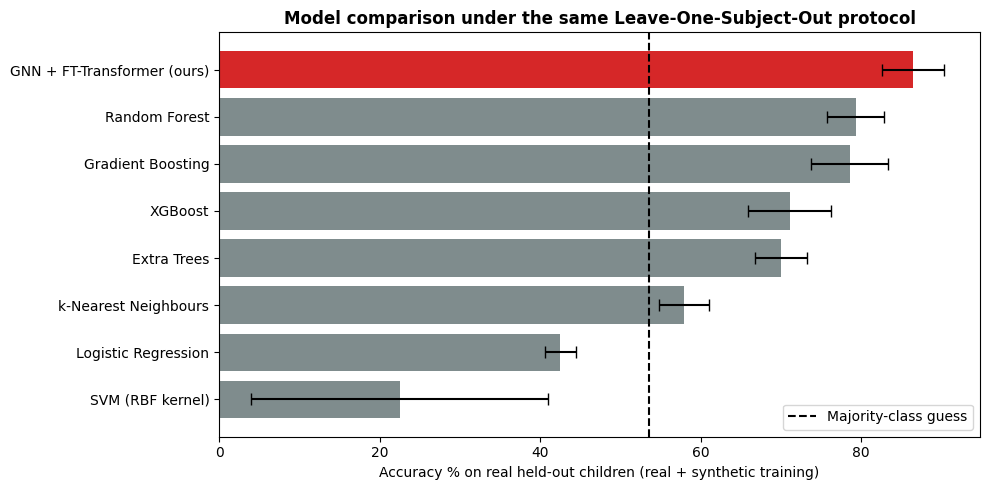

In [ ]:
# =========================================================================
# CELL 6c (NEW): COMPARISON TABLE (all numbers are on the 28 REAL held-out children)
# =========================================================================
def summarize(prob_matrix):
    a = np.array([accuracy_score(y_true, (p >= 0.5).astype(int)) for p in prob_matrix]) * 100
    u = np.array([roc_auc_score(y_true, p) for p in prob_matrix])
    return a.mean(), a.std(), u.mean(), u.std()

rows = []
for name in model_names:
    r_a, r_as, r_u, r_us = summarize(base_probs[(name, 'real only')])
    s_a, s_as, s_u, s_us = summarize(base_probs[(name, 'real + synthetic')])
    rows.append([name, f"{r_a:.1f} +/- {r_as:.1f}", f"{r_u:.3f}", f"{s_a:.1f} +/- {s_as:.1f}", f"{s_u:.3f}", s_a])

d_a, d_as, d_u, d_us = summarize(synth_probs)                      # your deep model, real + synthetic (Cell 5)
# Your deep model trained on real data only: from your earlier 10-seed run (seeds 0-9), entered as reference values.
rows.append(['GNN + FT-Transformer (ours)', "70.4 +/- 3.9", "0.754", f"{d_a:.1f} +/- {d_as:.1f}", f"{d_u:.3f}", d_a])

table = pd.DataFrame(rows, columns=['Model', 'Real only: accuracy %', 'Real only: AUC',
                                    'Real+synthetic: accuracy %', 'Real+synthetic: AUC', '_sort'])
table = table.sort_values('_sort', ascending=False).drop(columns='_sort').reset_index(drop=True)
print("=" * 100)
print(f"COMPARATIVE ANALYSIS: Leave-One-Subject-Out on {N} real children, mean +/- std over {len(BASE_SEEDS)} seeds")
print(f"Majority-class guess (the number to beat): {max(y_true.mean(), 1 - y_true.mean())*100:.1f}%")
print("=" * 100)
print(table.to_string(index=False))
print("=" * 100)
print("How to read this: with 28 children, ONE child changes accuracy by 3.6 points. Differences smaller than about")
print("7-10 points between two models are within noise and must not be presented as one model being better.")
table.to_csv('model_comparison.csv', index=False)

# bar chart: real + synthetic accuracy, with seed spread
names_sorted = table['Model'].tolist()
vals, errs = [], []
for n in names_sorted:
    if n.startswith('GNN'):
        vals.append(d_a); errs.append(d_as)
    else:
        a, s, _, _ = summarize(base_probs[(n, 'real + synthetic')]); vals.append(a); errs.append(s)
fig, ax = plt.subplots(figsize=(10, 5))
cols = ['#d62728' if n.startswith('GNN') else '#7f8c8d' for n in names_sorted]
ax.barh(names_sorted[::-1], vals[::-1], xerr=errs[::-1], color=cols[::-1], capsize=4)
ax.axvline(max(y_true.mean(), 1 - y_true.mean()) * 100, color='black', ls='--', label='Majority-class guess')
ax.set_xlabel('Accuracy % on real held-out children (real + synthetic training)'); ax.legend(loc='lower right')
ax.set_title('Model comparison under the same Leave-One-Subject-Out protocol', fontweight='bold')
plt.tight_layout(); plt.show()

In [ ]:
# =========== CELL 7: FINAL MODELS FOR NEW CHILDREN (trained on all 28 real children + synthetic) ===========
# Five models with different seeds are trained; their average is the risk score and their spread is the uncertainty.
# These models have no unbiased score of their own: the Cell 6 Leave-One-Subject-Out result is the performance estimate.
FINAL_SEEDS = [0, 1, 2, 3, 4]
final_models = [train_model(np.arange(N), s, use_synth=True) for s in FINAL_SEEDS]

def predict_new_child(eeg_features_8x3, mchat_23):
    # eeg_features_8x3: [8 channels, 3] = (CV, entropy, skewness); mchat_23: the 23 answers (0/1)
    e = np.asarray(eeg_features_8x3, dtype=np.float32).reshape(1, 8, 3)
    m = np.asarray(mchat_23, dtype=np.float32).reshape(1, 23)
    ps = np.array([predict_child(mdl, sc, e, build_adjacency(e), m)[0][0] for mdl, sc in final_models])
    return float(ps.mean()), float(ps.std())

mean_p, spread = predict_new_child(eeg_all[0], mchat_arr[0])
print(f"Demo (child 0, already in training, shown only to demonstrate the function): "
      f"risk score {mean_p*100:.1f}%  (spread across 5 models: +/- {spread*100:.1f} points)")
print("Screening-support prototype, not a diagnosis.")

save_dir = 'saved_models'
os.makedirs(save_dir, exist_ok=True)
for k, (mdl, sc) in enumerate(final_models):
    torch.save(mdl.state_dict(), os.path.join(save_dir, f'asd_model_seed{FINAL_SEEDS[k]}.pth'))
    joblib.dump(sc, os.path.join(save_dir, f'eeg_scaler_seed{FINAL_SEEDS[k]}.joblib'))
print("Saved to:", save_dir)

Demo (child 0, already in training, shown only to demonstrate the function): risk score 2.7%  (spread across 5 models: +/- 0.3 points)
Screening-support prototype, not a diagnosis.
Saved to: saved_models
